In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
df = pd.read_csv("Nigdi_OpenAQ_Hourly_Model_Ready.csv")

df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values("timestamp").reset_index(drop=True)

# Time features
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
df["month"] = df["timestamp"].dt.month

# Cyclical hour representation: 23:00 and 00:00 are near each other
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

# Cyclical wind-direction representation
df["wind_direction_sin"] = np.sin(np.radians(df["wind_direction"]))
df["wind_direction_cos"] = np.cos(np.radians(df["wind_direction"]))

In [3]:
# Historical PM2.5 features
for lag in [1, 2, 3, 6, 12, 24]:
    df[f"pm25_lag_{lag}"] = df["pm25"].shift(lag)

# Rolling means use only previous observations, never the current/future target
df["pm25_mean_3"] = df["pm25"].shift(1).rolling(3).mean()
df["pm25_mean_6"] = df["pm25"].shift(1).rolling(6).mean()
df["pm25_mean_24"] = df["pm25"].shift(1).rolling(24).mean()

# Target: PM2.5 one hour in the future
df["pm25_next_hour"] = df["pm25"].shift(-1)

# Do not use a target when there is an hourly timestamp gap
df["next_timestamp"] = df["timestamp"].shift(-1)
is_next_hour = (
    (df["next_timestamp"] - df["timestamp"])
    .dt.total_seconds()
    .eq(3600)
)

df.loc[~is_next_hour, "pm25_next_hour"] = np.nan

In [4]:
# Temperature and humidity intentionally excluded: more than 50% missing.
features = [
    "pm25", "pm10", "no2", "o3",
    "wind_speed",
    "wind_direction_sin", "wind_direction_cos",
    "hour_sin", "hour_cos",
    "day_of_week", "month",
    "pm25_lag_1", "pm25_lag_2", "pm25_lag_3",
    "pm25_lag_6", "pm25_lag_12", "pm25_lag_24",
    "pm25_mean_3", "pm25_mean_6", "pm25_mean_24"
]

model_df = df[features + ["pm25_next_hour", "timestamp"]].dropna(
    subset=["pm25_next_hour"]
).copy()

# Chronological 80/20 split
split_index = int(len(model_df) * 0.80)

train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]

X_train = train_df[features]
y_train = train_df["pm25_next_hour"]

X_test = test_df[features]
y_test = test_df["pm25_next_hour"]

print("Training observations:", len(train_df))
print("Testing observations:", len(test_df))

Training observations: 8549
Testing observations: 2138


In [5]:
model = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("gradient_boosting", GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.03,
        max_depth=3,
        loss="huber",
        random_state=42
    ))
])

model.fit(X_train, y_train)
predictions = model.predict(X_test)

In [8]:
# ML-model metrics
mae = mean_absolute_error(y_test, predictions)
rmse = mean_squared_error(y_test, predictions) ** 0.5
r2 = r2_score(y_test, predictions)

print(f"Gradient Boosting MAE:  {mae:.2f} µg/m³")
print(f"Gradient Boosting RMSE: {rmse:.2f} µg/m³")
print(f"Gradient Boosting R²:   {r2:.3f}")

# Persistence baseline:
# predict next-hour PM2.5 using the latest available PM2.5 reading.
# ffill() uses only earlier values, so it does not leak future information.

all_pm25 = pd.concat([X_train["pm25"], X_test["pm25"]]).ffill()

baseline_predictions = all_pm25.loc[X_test.index]

baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_rmse = mean_squared_error(y_test, baseline_predictions) ** 0.5
baseline_r2 = r2_score(y_test, baseline_predictions)

print("\nPersistence baseline:")
print(f"MAE:  {baseline_mae:.2f} µg/m³")
print(f"RMSE: {baseline_rmse:.2f} µg/m³")
print(f"R²:   {baseline_r2:.3f}")

Gradient Boosting MAE:  3.91 µg/m³
Gradient Boosting RMSE: 5.30 µg/m³
Gradient Boosting R²:   0.489

Persistence baseline:
MAE:  4.02 µg/m³
RMSE: 5.61 µg/m³
R²:   0.427


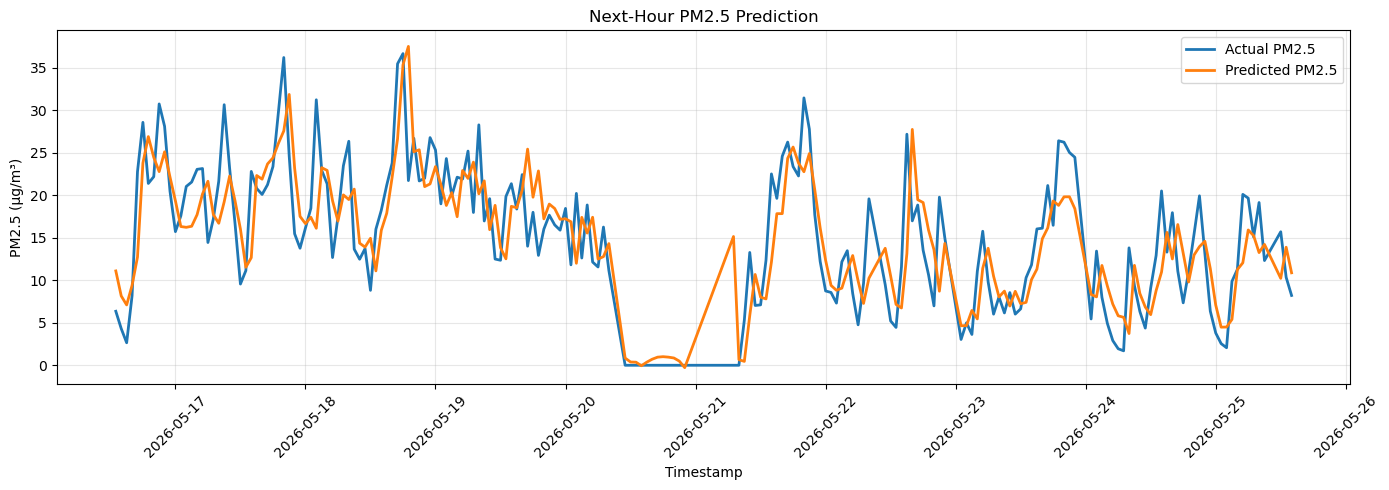

In [9]:
# Visual result
plt.figure(figsize=(14, 5))

plt.plot(
    test_df["timestamp"].iloc[:200],
    y_test.iloc[:200],
    label="Actual PM2.5",
    linewidth=2
)

plt.plot(
    test_df["timestamp"].iloc[:200],
    predictions[:200],
    label="Predicted PM2.5",
    linewidth=2
)

plt.title("Next-Hour PM2.5 Prediction")
plt.xlabel("Timestamp")
plt.ylabel("PM2.5 (µg/m³)")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
import joblib

joblib.dump(
    model,
    "nigdi_next_hour_pm25_gradient_boosting.pkl"
)

['nigdi_next_hour_pm25_gradient_boosting.pkl']

In [12]:
# Get importance values from Gradient Boosting model
importance = model.named_steps["gradient_boosting"].feature_importances_

# Get the actual feature names after imputation
feature_names = model.named_steps["imputer"].get_feature_names_out(features)

# Create feature-importance table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values("Importance", ascending=False)

print(importance_df)

                                Feature  Importance
0                                  pm25    0.908033
1                                  pm10    0.049612
19                         pm25_mean_24    0.013717
2                                   no2    0.013286
8                              hour_cos    0.006120
7                              hour_sin    0.002295
10                                month    0.001875
3                                    o3    0.001584
12                           pm25_lag_2    0.000644
11                           pm25_lag_1    0.000511
17                          pm25_mean_3    0.000457
5                    wind_direction_sin    0.000456
13                           pm25_lag_3    0.000365
16                          pm25_lag_24    0.000279
15                          pm25_lag_12    0.000265
18                          pm25_mean_6    0.000145
30         missingindicator_pm25_lag_12    0.000103
6                    wind_direction_cos    0.000091
14          

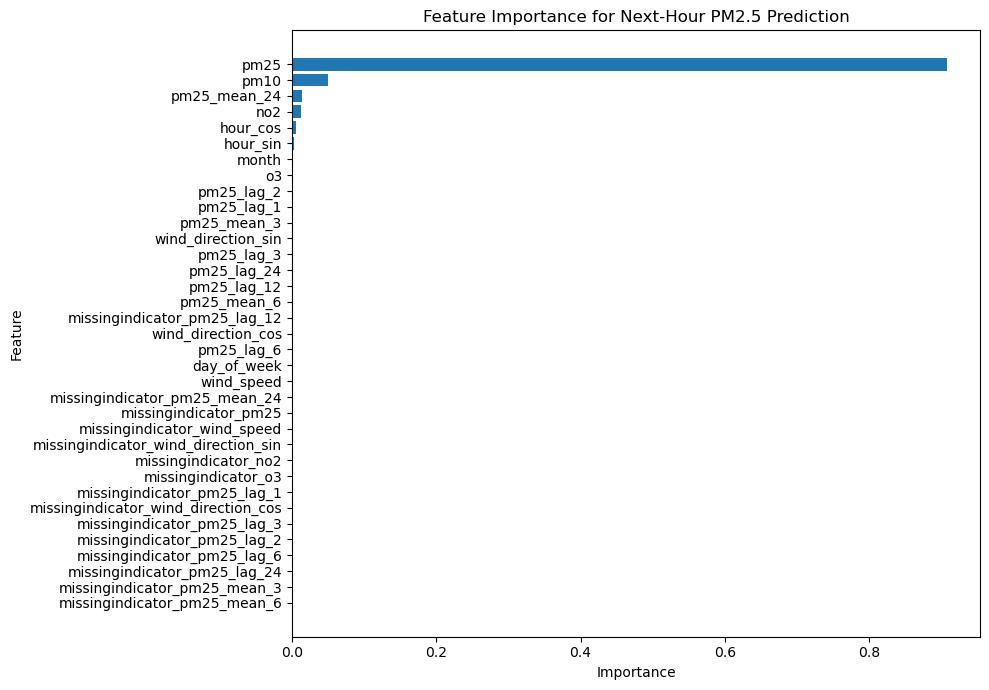

In [15]:
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.title("Feature Importance for Next-Hour PM2.5 Prediction")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [13]:
results_df = pd.DataFrame({
    "timestamp": test_df["timestamp"],
    "actual_pm25": y_test,
    "predicted_pm25": predictions
})

results_df.to_csv(
    "nigdi_pm25_hourly_prediction_results.csv",
    index=False
)

results_df.head()

,timestamp,actual_pm25,predicted_pm25
8742,2026-05-16 13:00:00+05:30,6.3475,11.087979
8743,2026-05-16 14:00:00+05:30,4.3075,8.146314
8744,2026-05-16 15:00:00+05:30,2.6450,7.092195
8745,2026-05-16 16:00:00+05:30,8.1700,9.391005
8746,2026-05-16 17:00:00+05:30,22.7600,12.717815
